In [31]:
from sklearn.datasets import fetch_california_housing

housing = fetch_california_housing(as_frame=True)
df = housing.frame
print(df.head())
print(df.shape)

X  = df[["MedInc"]]
y = df["MedHouseVal"]#target

print(X.shape)
print(y.shape)

   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  
(20640, 9)
(20640, 1)
(20640,)


In [32]:
# ( 70Train / 30Test Split)
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=42)

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(14448, 1)
(6192, 1)
(14448,)
(6192,)


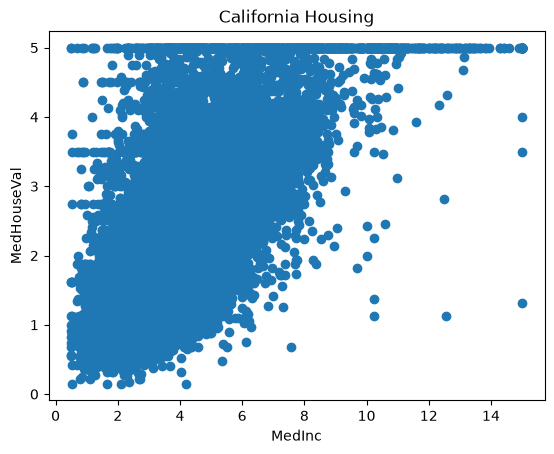

In [33]:
# (Scatter Plot)
import matplotlib.pyplot as plt

plt.scatter(X,y)
plt.xlabel("MedInc")
plt.ylabel("MedHouseVal")
plt.title("California Housing")

plt.show()

In [34]:

# y = ax+b 

from sklearn.linear_model import LinearRegression

model=LinearRegression()
model.fit(X_train,y_train)

print("slope:",model.coef_) #a
print("intercept:",model.intercept_) #b





slope: [0.41819327]
intercept: 0.4479496555604332


In [35]:
# R-squared
from sklearn.metrics import r2_score

y_pred=model.predict(X_test)
r2=r2_score(y_test,y_pred)
print("r_squared : ",r2)

r_squared :  0.47293192589970245


In [36]:
#1.2
# MedInc,HouseAge,AveRooms
print(df.head())


   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  


In [37]:
print(df[["MedInc", "HouseAge", "AveRooms"]].head())


   MedInc  HouseAge  AveRooms
0  8.3252      41.0  6.984127
1  8.3014      21.0  6.238137
2  7.2574      52.0  8.288136
3  5.6431      52.0  5.817352
4  3.8462      52.0  6.281853


In [ ]:
X=df[["MedInc", "HouseAge", "AveRooms"]]
y = df["MedHouseVal"]

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=42)

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

new_model=LinearRegression()
new_model.fit(X_train,y_train)

print("slope:",new_model.coef_) #3 ta shib
print("intercept:",new_model.intercept_) #b



(14448, 3)
(6192, 3)
(14448,)
(6192,)
slope: [ 0.44191756  0.01683785 -0.02551413]
intercept: 0.013574378569973788


In [45]:
new_y_pred= new_model.predict(X_test)

new_r2=r2_score(y_test,new_y_pred)

print("new_r_squared :" ,new_r2)
print("first_r2:",r2)

new_r_squared : 0.5126516784926669
first_r2: 0.47293192589970245


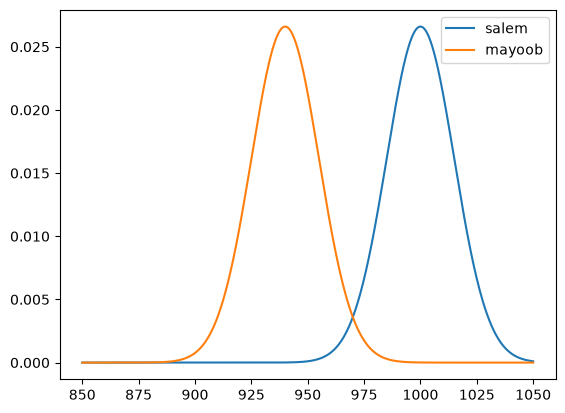

In [68]:
# 2
#Prior Probability
#  salem 92%
# mayoob 8%
p_salem=0.92
p_mayoob=0.08

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

salem_dist=norm(loc=1000,scale=15)
mayoob_dist=norm(940,15)

x = np.linspace(850,1050,1000)
# print(x)
salem_pdf=salem_dist.pdf(x)
mayoob_pdf=mayoob_dist.pdf(x)

plt.plot(x,salem_pdf,label="salem")
plt.plot(x,mayoob_pdf,label="mayoob")

# plt.xlabel("gr")
# plt.ylabel("chegali ehtemal")
# plt.title()
# plt.grid()
plt.legend()
plt.show()



In [69]:
x=970
salem_likelihood=salem_dist.pdf(x)
mayoob_likelihood=mayoob_dist.pdf(x)

#Prior Probability
#  salem 92%
# mayoob 8%
p_salem=0.92
p_mayoob=0.08
salem=salem_likelihood*p_salem
mayoob=mayoob_likelihood*p_mayoob
print(salem)
print(mayoob)

0.003311445946142201
0.0002879518214036697


In [70]:
Salem_N = salem / (salem + mayoob)

Mayoob_N = mayoob / (salem + mayoob)

print("Salem:", Salem_N)
print("Mayoob:", Mayoob_N)

Salem: 0.9199999999999999
Mayoob: 0.08


In [73]:
#B--2.4--KNN 
from sklearn.datasets import load_wine

X, y = load_wine(return_X_y=True)
print(X)
print(X.shape)
print(y)
print(y.shape)

[[1.423e+01 1.710e+00 2.430e+00 ... 1.040e+00 3.920e+00 1.065e+03]
 [1.320e+01 1.780e+00 2.140e+00 ... 1.050e+00 3.400e+00 1.050e+03]
 [1.316e+01 2.360e+00 2.670e+00 ... 1.030e+00 3.170e+00 1.185e+03]
 ...
 [1.327e+01 4.280e+00 2.260e+00 ... 5.900e-01 1.560e+00 8.350e+02]
 [1.317e+01 2.590e+00 2.370e+00 ... 6.000e-01 1.620e+00 8.400e+02]
 [1.413e+01 4.100e+00 2.740e+00 ... 6.100e-01 1.600e+00 5.600e+02]]
(178, 13)
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2]
(178,)


In [76]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=42,stratify=y)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(124, 13)
(54, 13)
(124,)
(54,)


In [77]:
# StandardScaler
from sklearn.preprocessing import StandardScaler

scaler=StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [80]:
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import accuracy_score

knn_model1=KNeighborsClassifier(n_neighbors=1)
knn_model1.fit(X_train_scaled,y_train)

y_pred1=knn_model1.predict(X_test_scaled)
accuracy1=accuracy_score(y_test,y_pred1)
print(accuracy1)


0.9629629629629629


In [83]:
knn_model5=KNeighborsClassifier(n_neighbors=5)
knn_model5.fit(X_train_scaled,y_train)
y_pred5=knn_model5.predict(X_test_scaled)
accuracy5=accuracy_score(y_test,y_pred5)
print(accuracy5)

0.9444444444444444


In [84]:
knn_model15=KNeighborsClassifier(n_neighbors=15)
knn_model15.fit(X_train_scaled,y_train)
y_pred15=knn_model15.predict(X_test_scaled)
accuracy15=accuracy_score(y_test,y_pred15)
print(accuracy15)

0.9814814814814815


In [122]:
#3
import pandas as pd

df=pd.read_csv("titanic.csv")
df.head(10)
# df[["Pclass","Sex","Age","Fare"]]


,PassengerId,Survived,Pclass,Lname,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,Braund,Mr. Owen Harris,male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,Cumings,Mrs. John Bradley (Florence Briggs Thayer),female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,Heikkinen,Miss. Laina,female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,Futrelle,Mrs. Jacques Heath (Lily May Peel),female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,Allen,Mr. William Henry,male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,Moran,Mr. James,male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,McCarthy,Mr. Timothy J,male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,Palsson,Master. Gosta Leonard,male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,Johnson,Mrs. Oscar W (Elisabeth Vilhelmina Berg),female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,Nasser,Mrs. Nicholas (Adele Achem),female,14.0,1,0,237736,30.0708,NaN,C


In [123]:
print(df["Age"].isna().sum())
df.isnull().sum()

30


PassengerId      0
Survived         0
Pclass           0
Lname            0
Name             0
Sex              0
Age             30
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          125
Embarked         1
dtype: int64

In [124]:
mean_age=df["Age"].mean()
print(mean_age)

28.141507936507935


In [125]:
df["Age"]=df["Age"].fillna(mean_age)

In [126]:
print(df["Age"].isna().sum())
df.isnull().sum()

0


PassengerId      0
Survived         0
Pclass           0
Lname            0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          125
Embarked         1
dtype: int64

In [127]:
df = pd.get_dummies(df,columns=["Sex"],drop_first=True)
df.head()


,PassengerId,Survived,Pclass,Lname,Name,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Sex_male
0,1,0,3,Braund,Mr. Owen Harris,22.0,1,0,A/5 21171,7.2500,NaN,S,True
1,2,1,1,Cumings,Mrs. John Bradley (Florence Briggs Thayer),38.0,1,0,PC 17599,71.2833,C85,C,False
2,3,1,3,Heikkinen,Miss. Laina,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,False
3,4,1,1,Futrelle,Mrs. Jacques Heath (Lily May Peel),35.0,1,0,113803,53.1000,C123,S,False
4,5,0,3,Allen,Mr. William Henry,35.0,0,0,373450,8.0500,NaN,S,True


In [128]:
print(df.columns.tolist())

['PassengerId', 'Survived', 'Pclass', 'Lname', 'Name', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked', 'Sex_male']


In [143]:
X=df[["Pclass","Sex_male","Age","Fare"]]
y=df["Survived"]
print(X.head())
print(y.head())


   Pclass  Sex_male   Age     Fare
0       3      True  22.0   7.2500
1       1     False  38.0  71.2833
2       3     False  26.0   7.9250
3       1     False  35.0  53.1000
4       3      True  35.0   8.0500
0    0
1    1
2    1
3    1
4    0
Name: Survived, dtype: int64


In [144]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=42,stratify=y)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(109, 4)
(47, 4)
(109,)
(47,)


In [148]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print(X_train_scaled.shape)
print(X_test_scaled.shape)

(109, 4)
(47, 4)


In [149]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()

model.fit(X_train_scaled, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [153]:
y_pred =model.predict(X_test_scaled)
print(y_pred)

from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print(accuracy)

[0 1 1 0 1 0 1 0 0 0 0 0 1 0 1 1 0 0 1 1 0 0 0 0 1 0 1 1 0 0 1 0 0 0 0 1 0
 0 0 1 1 0 0 0 0 1 0]
0.8085106382978723


In [154]:
# 3.2
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[26  5]
 [ 4 12]]


In [ ]:
# X=df[["Pclass","Sex_male","Age","Fare"]]
print(model.coef_)
print(model.intercept_)

[[-0.54664886 -1.18387879 -0.25454177 -0.31211797]]
[-0.80399693]


In [157]:
#3.3
# cross_entropy_loss(p,y)
print(model.classes_)
y_proba = model.predict_proba(X_test_scaled)

print(y_proba[:5])

[0 1]
[[0.85102519 0.14897481]
 [0.32232688 0.67767312]
 [0.32613498 0.67386502]
 [0.8361164  0.1638836 ]
 [0.1807835  0.8192165 ]]


In [159]:
from sklearn.metrics import log_loss

loss = log_loss(y_test, y_proba)

print(loss)

0.4158893809550324


In [160]:
# parte akhar pish binie ghalat , dorost

y=1
p=0.9
import numpy as np

loss_correct = -np.log(0.9)
print(loss_correct)

y=1
p=0.1
loss_wrong = -np.log(0.1)
print(loss_wrong)

0.10536051565782628
2.3025850929940455


In [174]:
#4
# 240(h) + 60(porkhatar) =300
ph=240/300
print(ph)

pr=60/300
print(pr)

giniroot=1-((0.8**2)+(0.2**2))
print(giniroot)#root
print("--------------------------")
#left 180(h)+10(risk)=190
phleft=180/190
print(phleft)

prleft=10/190
print(prleft)

gini_left=1-((0.9473**2)+(0.0526**2))
print(gini_left)

print("--------------------------")
# 60 h +50 r =110
phright=60/110
print(phright)

prright=50/110
print(prright)

gini_right=1-((0.5454**2)+(0.4545**2))
print(gini_right)

print("--------------------------")
gini_weighted=190/300*0.0998+110/300*0.4959
print(gini_weighted)
print("--------------------------")
ginigain=giniroot-gini_weighted
print(ginigain)


0.8
0.2
0.31999999999999984
--------------------------
0.9473684210526315
0.05263157894736842
0.09985594999999992
--------------------------
0.5454545454545454
0.45454545454545453
0.49596858999999993
--------------------------
0.24503666666666665
--------------------------
0.07496333333333319


In [180]:
#entropy
#root
ph=240/300
print(ph)

pr=60/300
print(pr)

entropy_root= -(ph* np.log2(0.8)+pr* np.log2(0.2))
print("entropy root: ",entropy_root)


0.8
0.2
entropy root:  0.7219280948873623


In [176]:
phleft=180/190
print(phleft)

prleft=10/190
print(prleft)

entropy_left= -(phleft *np.log2(phleft)+(prleft* np.log2(prleft)))
print("entropy left: ",entropy_left)

0.9473684210526315
0.05263157894736842
entropy left:  0.2974722489192896


In [175]:
phright=60/110
print(phright)

prright=50/110
print(prright)

entropy_right= -(phright *np.log2(phright)+(prright* np.log2(prright)))
print("entropy right: ",entropy_right)

0.5454545454545454
0.45454545454545453
entropy right:  0.9940302114769565


In [182]:
entropy_weighted=190/300*0.7219+110/300*0.2974
print(entropy_weighted)

0.5662499999999999


In [183]:
information_gain=entropy_root-entropy_weighted
print(information_gain)

0.1556780948873624


In [ ]:
#4.2
# XOR

In [185]:
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import accuracy_score

tree_model = DecisionTreeClassifier(max_depth=4, random_state=42)
tree_model.fit(X_train, y_train)
y_pred_tree = tree_model.predict(X_test)

tree_accuracy = accuracy_score(y_test, y_pred_tree)
print(tree_accuracy)
print(accuracy)

0.7872340425531915
0.8085106382978723


In [ ]:
print(tree_model.feature_importances_)
# ["Pclass", "Sex_male", "Age", "Fare"]. features

[0.0771361  0.55924149 0.12114878 0.24247364]


In [196]:
#4.4
import pandas as pd

df = pd.read_csv("heart.csv")
df.head(10)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1
5,57,1,0,140,192,0,1,148,0,0.4,1,0,1,1
6,56,0,1,140,294,0,0,153,0,1.3,1,0,2,1
7,44,1,1,120,263,0,1,173,0,0.0,2,0,3,1
8,52,1,2,172,199,1,1,162,0,0.5,2,0,3,1
9,57,1,2,150,168,0,1,174,0,1.6,2,0,2,1


In [195]:
print(df.shape)

print(df.isnull().sum())

print(df["target"].value_counts())


(303, 14)
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64
target
1    165
0    138
Name: count, dtype: int64


In [198]:
X = df[["age", "chol", "thal"]]
y = df["target"]
print(X)
print(y)
print(X.shape)
print(y.shape)

     age  chol  thal
0     63   233     1
1     37   250     2
2     41   204     2
3     56   236     2
4     57   354     2
..   ...   ...   ...
298   57   241     3
299   45   264     3
300   68   193     3
301   57   131     3
302   57   236     2

[303 rows x 3 columns]
0      1
1      1
2      1
3      1
4      1
      ..
298    0
299    0
300    0
301    0
302    0
Name: target, Length: 303, dtype: int64
(303, 3)
(303,)


In [199]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(212, 3)
(91, 3)
(212,)
(91,)


In [202]:
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import accuracy_score

model_tree1 = DecisionTreeClassifier(random_state=42)

model_tree1.fit(X_train, y_train)

y_pred1 = model_tree1.predict(X_test)
test_accuracy = accuracy_score(y_test,y_pred1)
print("Test Accuracy:", test_accuracy)

y_train_pred1 = model_tree1.predict(X_train)
train_accuracy = accuracy_score(y_train, y_train_pred1)
print("Train Accuracy:",train_accuracy)


Test Accuracy: 0.6263736263736264
Train Accuracy: 1.0


In [206]:
model_tree2 = DecisionTreeClassifier(min_samples_leaf=20, random_state=42)

model_tree2.fit(X_train, y_train) 


model_tree2.fit(X_train, y_train)

y_train_pred2 = model_tree2.predict(X_train)
y_test_pred2 = model_tree2.predict(X_test)

train_accuracy2 = accuracy_score(y_train, y_train_pred2)
test_accuracy2 = accuracy_score(y_test, y_test_pred2)

print("Tree 2 Train:", train_accuracy2)
print("Tree 2 Test:", test_accuracy)


Tree 2 Train: 0.7735849056603774
Tree 2 Test: 0.6263736263736264


In [208]:
model_tree3 = DecisionTreeClassifier(max_leaf_nodes=8,random_state=42)

model_tree3.fit(X_train, y_train)

y_train_pred3 = model_tree3.predict(X_train)
y_test_pred3 = model_tree3.predict(X_test)

train_accuracy3 = accuracy_score(y_train, y_train_pred3)
test_accuracy3 = accuracy_score(y_test, y_test_pred3)

print("Tree 3 Train:", train_accuracy3)
print("Tree 3 Test:", test_accuracy3)

Tree 3 Train: 0.8207547169811321
Tree 3 Test: 0.6703296703296703
